# Milestone 1: Text → embedding baseline

**IE 7615 Generative Project, Study Group 6**

This notebook builds the text side of our text-to-image pipeline on the cleaned COCO 2017 val pairs
(`data/processed/pairs.csv`, produced by `src/prepare_dataset.py`):

1. Caption statistics and CLIP tokenisation (77-token context).
2. **CLIP ViT-B/32** text and image embeddings for every pair, saved for later evaluation (CLIP score, retrieval).
3. Sanity check that the embeddings are aligned: matched vs. mismatched cosine similarity and text→image retrieval.
4. The **Stable Diffusion v1.5 conditioning**: how a prompt becomes the 77 × 768 CLIP ViT-L/14 embedding that the
   U-Net attends to, and the empty-prompt embedding used for classifier-free guidance.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor, CLIPTokenizer, CLIPTextModel

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
pairs = pd.read_csv(DATA / "pairs.csv")
stats = json.loads((DATA / "stats.json").read_text())
print(f"{len(pairs):,} images, {stats['captions_kept']:,} captions, device = {DEVICE}")
pairs.head()

/Users/sankalphegde/Desktop/deep learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


4,958 images, 24,788 captions, device = mps


,image_id,file,caption,n_captions,all_captions
0,139,images/000000000139.jpg,A living area with a television and a table,5,"[""A woman stands in the dining area at the tab..."
1,285,images/000000000285.jpg,A close up picture of a brown bear's face,5,"[""A big burly grizzly bear is show with grass ..."
2,632,images/000000000632.jpg,"Bedroom scene with a bookcase, blue comforter ...",5,"[""Bedroom scene with a bookcase, blue comforte..."
3,724,images/000000000724.jpg,A stop sign put upside down on a metal pole,5,"[""A stop sign is mounted upside-down on it's p..."
4,776,images/000000000776.jpg,A group of three stuffed animal teddy bears,5,"[""Three teddy bears, each a different color, s..."


## 1. Captions and tokenisation

words per caption: mean 10.4, max 38
CLIP tokens per caption: mean 12.8, max 51, truncated at 77: 0


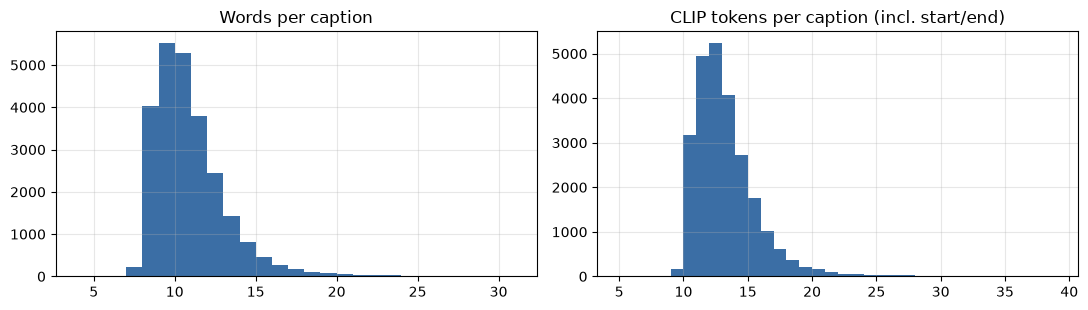

In [2]:
clip_id = "openai/clip-vit-base-patch32"
tok = CLIPTokenizer.from_pretrained(clip_id)
all_caps = [c for cs in pairs.all_captions.map(json.loads) for c in cs]
n_tokens = np.array([len(tok(c).input_ids) for c in all_caps])
words = np.array([len(c.split()) for c in all_caps])
print(f"words per caption: mean {words.mean():.1f}, max {words.max()}")
print(f"CLIP tokens per caption: mean {n_tokens.mean():.1f}, max {n_tokens.max()}, "
      f"truncated at 77: {(n_tokens > 77).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(words, bins=range(4, 32), color="#3b6ea5"); ax[0].set_title("Words per caption")
ax[1].hist(n_tokens, bins=range(5, 40), color="#3b6ea5"); ax[1].set_title("CLIP tokens per caption (incl. start/end)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [3]:
example = pairs.caption.iloc[0]
ids = tok(example).input_ids
print(example)
print(ids)
print(tok.convert_ids_to_tokens(ids))

A living area with a television and a table
[49406, 320, 2815, 2445, 593, 320, 8608, 537, 320, 2175, 49407]
['<|startoftext|>', 'a</w>', 'living</w>', 'area</w>', 'with</w>', 'a</w>', 'television</w>', 'and</w>', 'a</w>', 'table</w>', '<|endoftext|>']


## 2. CLIP ViT-B/32 text and image embeddings

In [4]:
model = CLIPModel.from_pretrained(clip_id).to(DEVICE).eval()
proc = CLIPProcessor.from_pretrained(clip_id)

@torch.no_grad()
def embed_text(texts, bs=256):
    out = []
    for i in range(0, len(texts), bs):
        t = proc(text=texts[i:i + bs], return_tensors="pt", padding=True, truncation=True).to(DEVICE)
        feats = model.text_projection(model.text_model(input_ids=t.input_ids, attention_mask=t.attention_mask).pooler_output)
        out.append(torch.nn.functional.normalize(feats, dim=-1).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def embed_images(paths, bs=64):
    out = []
    for i in range(0, len(paths), bs):
        ims = [Image.open(DATA / p).convert("RGB") for p in paths[i:i + bs]]
        x = proc(images=ims, return_tensors="pt").to(DEVICE)
        feats = model.visual_projection(model.vision_model(pixel_values=x.pixel_values).pooler_output)
        out.append(torch.nn.functional.normalize(feats, dim=-1).cpu())
    return torch.cat(out).numpy()

T = embed_text(pairs.caption.tolist())
I = embed_images(pairs.file.tolist())
np.savez_compressed(DATA / "clip_vitb32_embeddings.npz", text=T, image=I, image_id=pairs.image_id.values)
print("text", T.shape, "image", I.shape)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 74740.68it/s]

text (4958, 512) image (4958, 512)


## 3. Are text and image embeddings aligned?

cosine similarity  matched 0.305 ± 0.033   random pairs 0.154 ± 0.040


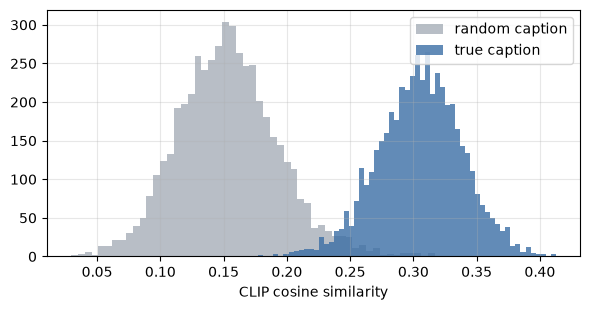

In [5]:
matched = (T * I).sum(1)
rng = np.random.default_rng(0)
mismatched = (T * I[rng.permutation(len(I))]).sum(1)
print(f"cosine similarity  matched {matched.mean():.3f} ± {matched.std():.3f}   "
      f"random pairs {mismatched.mean():.3f} ± {mismatched.std():.3f}")
plt.figure(figsize=(6, 3.2))
plt.hist(mismatched, bins=60, alpha=.7, label="random caption", color="#9aa3ae")
plt.hist(matched, bins=60, alpha=.8, label="true caption", color="#3b6ea5")
plt.xlabel("CLIP cosine similarity"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [6]:
def recall_at_k(T, I, ks=(1, 5, 10)):
    sims = T @ I.T                              # caption i should retrieve image i
    rank = (sims > sims[np.arange(len(T)), np.arange(len(T))][:, None]).sum(1)
    return {f"R@{k}": float((rank < k).mean()) for k in ks}

r1k = recall_at_k(T[:1000], I[:1000]); rall = recall_at_k(T, I)
print("text → image retrieval, 1,000 pairs:", {k: round(v, 3) for k, v in r1k.items()})
print(f"text → image retrieval, {len(T):,} pairs:", {k: round(v, 3) for k, v in rall.items()})
json.dump({"cos_matched": float(matched.mean()), "cos_random": float(mismatched.mean()),
           "retrieval_1k": r1k, "retrieval_all": rall}, open(DATA / "embedding_baseline.json", "w"), indent=2)

text → image retrieval, 1,000 pairs: {'R@1': 0.515, 'R@5': 0.801, 'R@10': 0.9}
text → image retrieval, 4,958 pairs: {'R@1': 0.295, 'R@5': 0.546, 'R@10': 0.662}


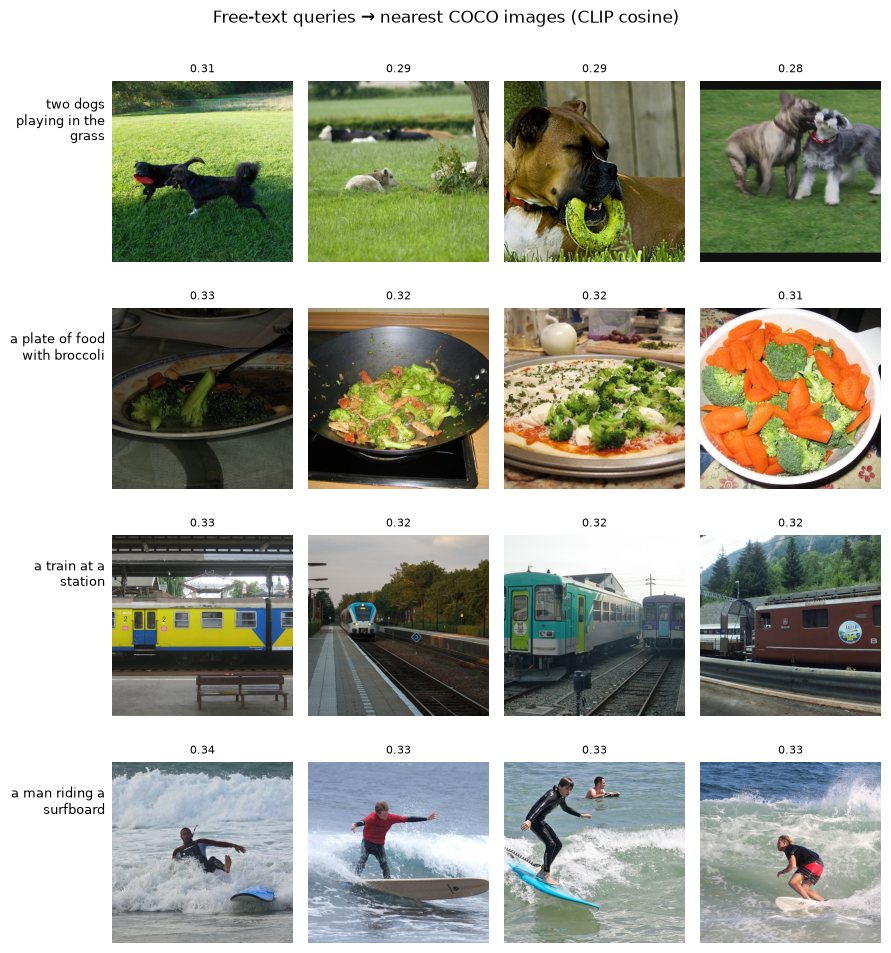

In [7]:
q = ["two dogs playing in the grass", "a plate of food with broccoli", "a train at a station", "a man riding a surfboard"]
qe = embed_text(q)
fig, axes = plt.subplots(len(q), 4, figsize=(9, 2.4 * len(q)))
for r, (text, e) in enumerate(zip(q, qe)):
    top = np.argsort(-(I @ e))[:4]
    for c, j in enumerate(top):
        axes[r, c].imshow(Image.open(DATA / pairs.file.iloc[j])); axes[r, c].axis("off")
        axes[r, c].set_title(f"{(I[j] @ e):.2f}", fontsize=8)
    axes[r, 0].text(-20, 112, text, ha="right", va="center", fontsize=9, wrap=True)
plt.suptitle("Free-text queries → nearest COCO images (CLIP cosine)", y=1.0); plt.tight_layout(); plt.show()

## 4. Stable Diffusion v1.5 text conditioning (CLIP ViT-L/14)

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 11186.03it/s]

conditioning embedding: (1, 77, 768) | unconditional (empty prompt, for CFG): (1, 77, 768)
classifier-free guidance:  eps = eps(uncond) + w · (eps(cond) − eps(uncond)),  w = guidance scale


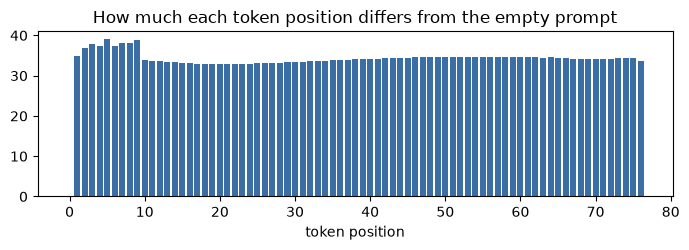

In [8]:
sd_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
sd_tok = CLIPTokenizer.from_pretrained(sd_id, subfolder="tokenizer")
sd_enc = CLIPTextModel.from_pretrained(sd_id, subfolder="text_encoder", variant="fp16", torch_dtype=torch.float16).to(DEVICE)

@torch.no_grad()
def sd_condition(prompt):
    ids = sd_tok(prompt, padding="max_length", max_length=sd_tok.model_max_length, truncation=True, return_tensors="pt").input_ids
    return sd_enc(ids.to(DEVICE)).last_hidden_state          # (1, 77, 768): one vector per token, fed to U-Net cross-attention

cond, uncond = sd_condition(pairs.caption.iloc[0]), sd_condition("")
print("conditioning embedding:", tuple(cond.shape), "| unconditional (empty prompt, for CFG):", tuple(uncond.shape))
print("classifier-free guidance:  eps = eps(uncond) + w · (eps(cond) − eps(uncond)),  w = guidance scale")
diff = (cond - uncond).float().norm(dim=-1)[0].cpu()
plt.figure(figsize=(7, 2.6)); plt.bar(range(77), diff, color="#3b6ea5")
plt.title("How much each token position differs from the empty prompt"); plt.xlabel("token position"); plt.tight_layout(); plt.show()